# Appendix A: The Queueing & Renewal Theory Rosetta Stone — Python Laboratory
### *Executable Reference Implementations, The Universal Queueing Calculator, and Automated Fleet Diagnostics*

**[Course Home](../README.md) | [Conceptual Track](../conceptual/10_appendix_the_queueing_theory_rosetta_stone.ipynb) | [Prev: Ch 09](../python/09_jackson_networks_and_bottleneck_routing.ipynb) | [Next: Appendix 11](../python/11_appendix_queueing_theory_of_flaky_tests_and_ci.ipynb)**

---

## Laboratory Overview & Objectives
1. Implement the **Universal Queueing Calculator Toolkit**: a unified library of analytical formulas for $M/M/1$, $M/M/c$ (Erlang-C), $M/M/c/c$ (Erlang-B), $M/G/1$ (Pollaczek-Khinchine), $G/G/c$ (Kingman), Cobham Multi-Class Priority, and Inspection Paradox residual life.
2. Build an **Automated Fleet Diagnostic Recommender** that analyzes empirical telemetry (arrival rates, service moments, server count) and outputs the recommended queueing model, expected wait times, and capacity headroom warnings.
3. Generate publication-grade comparative dashboards benchmarking all major models side-by-side.


In [1]:
import numpy as np
import scipy.stats as stats
import scipy.special as sp
import matplotlib.pyplot as plt

# Plotting style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 11
plt.rcParams['figure.dpi'] = 120

print("Environment initialized.")


Environment initialized.


---
## Part 1: The Universal Queueing Calculator Engine

We implement vectorized, numerically stable Python functions for the canonical queueing models.


In [2]:
class QueueingToolkit:
    """
    Unified analytical calculator for queueing and renewal models.
    """
    
    @staticmethod
    def mm1(lam, mu):
        rho = lam / mu
        if rho >= 1.0:
            return {"stable": False, "rho": rho}
        e_n = rho / (1.0 - rho)
        e_nq = (rho**2) / (1.0 - rho)
        e_wq = rho / (mu * (1.0 - rho))
        e_t = 1.0 / (mu * (1.0 - rho))
        return {"stable": True, "rho": rho, "E_N": e_n, "E_Nq": e_nq, "E_Wq": e_wq, "E_T": e_t}
        
    @staticmethod
    def erlang_c(c, a):
        """
        Computes Erlang-C probability of queuing C(c, a) and expected wait time.
        a = lambda / mu (offered load), c = server count.
        """
        rho = a / c
        if rho >= 1.0:
            return {"stable": False, "rho": rho}
            
        # Stable log-space computation for Erlang-C
        # sum_{k=0}^{c-1} a^k / k!
        terms = [a**k / sp.factorial(k) for k in range(c)]
        sum_terms = sum(terms)
        last_term = (a**c / sp.factorial(c)) / (1.0 - rho)
        c_prob = last_term / (sum_terms + last_term)
        
        return {"stable": True, "rho": rho, "erlang_c": c_prob}
        
    @staticmethod
    def mmc(lam, mu, c):
        a = lam / mu
        rho = a / c
        if rho >= 1.0:
            return {"stable": False, "rho": rho}
        ec = QueueingToolkit.erlang_c(c, a)["erlang_c"]
        e_wq = ec / (c * mu * (1.0 - rho))
        e_t = e_wq + (1.0 / mu)
        e_nq = lam * e_wq
        e_n = lam * e_t
        return {"stable": True, "rho": rho, "erlang_c": ec, "E_Wq": e_wq, "E_T": e_t, "E_Nq": e_nq, "E_N": e_n}
        
    @staticmethod
    def mg1_pk(lam, mean_s, std_s):
        rho = lam * mean_s
        if rho >= 1.0:
            return {"stable": False, "rho": rho}
        e_s2 = mean_s**2 + std_s**2
        cs2 = (std_s / mean_s)**2
        w0 = lam * e_s2 / 2.0
        e_wq = w0 / (1.0 - rho)
        e_t = e_wq + mean_s
        return {"stable": True, "rho": rho, "c_s2": cs2, "E_Wq": e_wq, "E_T": e_t, "W_0": w0}
        
    @staticmethod
    def kingman_ggc(lam, mean_s, cv_a, cv_s, c=1):
        mu = 1.0 / mean_s
        rho = lam / (c * mu)
        if rho >= 1.0:
            return {"stable": False, "rho": rho}
        var_factor = (cv_a**2 + cv_s**2) / 2.0
        e_wq = (rho / (1.0 - rho)) * var_factor * (mean_s / c)
        e_t = e_wq + mean_s
        shadow_price = (1.0 / (1.0 - rho)**2) * var_factor * (mean_s / c)
        return {"stable": True, "rho": rho, "E_Wq": e_wq, "E_T": e_t, "shadow_price": shadow_price}

print("QueueingToolkit defined.")


QueueingToolkit defined.


---
## Part 2: Automated Fleet Diagnostic & Sizing Engine

We build an automated diagnostic function that accepts real-world telemetry parameters and recommends the appropriate queueing model and capacity headroom.


In [3]:
def diagnose_fleet(arrival_rate_per_hr, mean_duration_min, std_duration_min, server_count, cv_arrivals=1.0):
    """
    Automated diagnostic engine for sizing computing fleets.
    """
    lam = arrival_rate_per_hr / 60.0 # jobs per minute
    mean_s = mean_duration_min
    std_s = std_duration_min
    cv_s = std_s / mean_s
    mu = 1.0 / mean_s
    
    rho = lam / (server_count * mu)
    
    print("=" * 70)
    print("FLEET TELEMETRY & QUEUEING DIAGNOSTIC REPORT")
    print("=" * 70)
    print(f"Arrival Rate (lambda):        {arrival_rate_per_hr:.1f} jobs/hr ({lam:.3f} jobs/min)")
    print(f"Mean Job Duration (E[S]):     {mean_duration_min:.1f} minutes")
    print(f"Job Duration Std Dev:         {std_duration_min:.1f} minutes (c_s = {cv_s:.2f})")
    print(f"Arrival Burstiness (c_a):     {cv_arrivals:.2f}")
    print(f"Parallel Worker Fleet:        c = {server_count} nodes")
    print(f"Fleet Traffic Intensity (rho): {rho*100:.2f}%\n")
    
    # Model Selection Diagnostics
    if rho >= 1.0:
        print("[CRITICAL ALERT] Fleet is mathematically UNSTABLE (rho >= 100%)!")
        print("Queue length will grow infinitely. Immediate capacity expansion required.")
        return
        
    # Kingman Evaluation
    kingman = QueueingToolkit.kingman_ggc(lam, mean_s, cv_arrivals, cv_s, c=server_count)
    
    print(f"Expected Queue Wait Time E[W_q]:  {kingman['E_Wq']:.2f} minutes")
    print(f"Total Turnaround Time E[T]:       {kingman['E_T']:.2f} minutes")
    print(f"Capacity Shadow Price (dWq/drho): {kingman['shadow_price']:.1f} min/unit load\n")
    
    # Warnings & Prescriptions
    if rho > 0.85:
        print("[WARNING] Utilization is above the 85% Congestion Knee!")
        print(f"  A 5% load increase will inflate queue wait time by {((rho+0.05)/(1-(rho+0.05))) / (rho/(1-rho)) * 100 - 100:.1f}%.")
    if cv_s > 1.5:
        print(f"[OPPORTUNITY] Service time coefficient of variation is high (c_s = {cv_s:.2f}).")
        print("  Implementing build caching or test timeouts will yield super-linear latency reduction.")
    if cv_arrivals > 1.2:
        print(f"[OPPORTUNITY] Arrival stream is bursty (c_a = {cv_arrivals:.2f}).")
        print("  Enforcing token-bucket arrival smoothing will significantly drop wait times.")
        
    print("=" * 70)

# Run diagnostic on a realistic enterprise CI workload
diagnose_fleet(arrival_rate_per_hr=320.0, mean_duration_min=12.0, std_duration_min=20.0, server_count=70, cv_arrivals=1.4)


FLEET TELEMETRY & QUEUEING DIAGNOSTIC REPORT
Arrival Rate (lambda):        320.0 jobs/hr (5.333 jobs/min)
Mean Job Duration (E[S]):     12.0 minutes
Job Duration Std Dev:         20.0 minutes (c_s = 1.67)
Arrival Burstiness (c_a):     1.40
Parallel Worker Fleet:        c = 70 nodes
Fleet Traffic Intensity (rho): 91.43%

Expected Queue Wait Time E[W_q]:  4.33 minutes
Total Turnaround Time E[T]:       16.33 minutes
Capacity Shadow Price (dWq/drho): 55.3 min/unit load

[WARNING] Utilization is above the 85% Congestion Knee!
  A 5% load increase will inflate queue wait time by 153.1%.
[OPPORTUNITY] Service time coefficient of variation is high (c_s = 1.67).
  Implementing build caching or test timeouts will yield super-linear latency reduction.
[OPPORTUNITY] Arrival stream is bursty (c_a = 1.40).
  Enforcing token-bucket arrival smoothing will significantly drop wait times.


---
## Part 3: Model Shootout Comparison Dashboard

We plot a multi-model comparative dashboard comparing $M/M/1$, $M/G/1$ (Low Variance vs High Variance), and $G/G/1$ across utilization $\rho \in [0.10, 0.95]$.


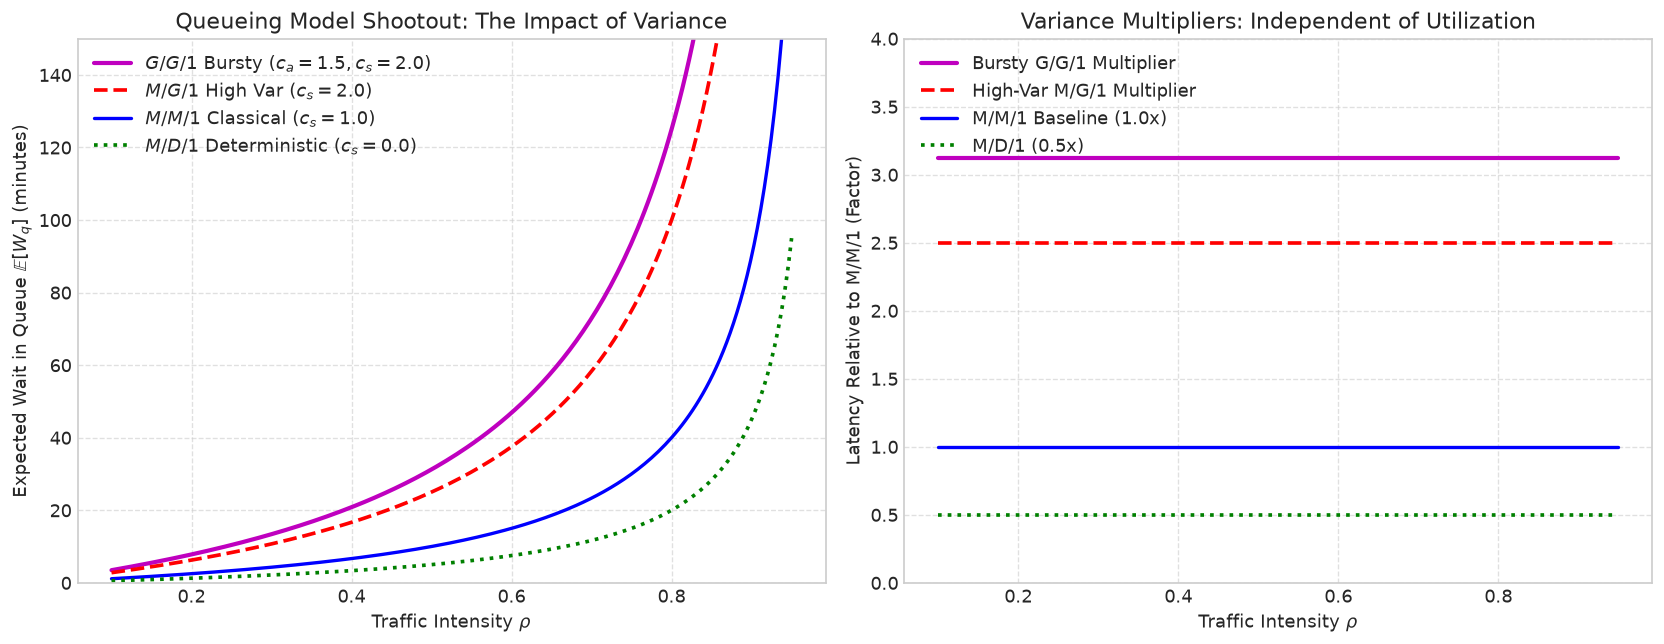

In [4]:
rhos = np.linspace(0.10, 0.95, 200)
mean_s = 10.0 # 10 minutes

# 1. M/M/1: cs = 1.0, ca = 1.0
wq_mm1 = (rhos / (1.0 - rhos)) * 1.0 * mean_s

# 2. M/D/1: cs = 0.0, ca = 1.0 (Deterministic service)
wq_md1 = (rhos / (1.0 - rhos)) * 0.5 * mean_s

# 3. M/G/1 High Variance: cs = 2.0, ca = 1.0
wq_mg1_high = (rhos / (1.0 - rhos)) * ((1.0 + 2.0**2) / 2.0) * mean_s

# 4. G/G/1 Bursty & Heavy Tail: cs = 2.0, ca = 1.5
wq_gg1_bursty = (rhos / (1.0 - rhos)) * ((1.5**2 + 2.0**2) / 2.0) * mean_s

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

# Subplot 1: Linear Scale Comparison
ax1.plot(rhos, wq_gg1_bursty, 'm-', lw=2.5, label=r"$G/G/1$ Bursty ($c_a=1.5, c_s=2.0$)")
ax1.plot(rhos, wq_mg1_high, 'r--', lw=2.2, label=r"$M/G/1$ High Var ($c_s=2.0$)")
ax1.plot(rhos, wq_mm1, 'b-', lw=2.0, label=r"$M/M/1$ Classical ($c_s=1.0$)")
ax1.plot(rhos, wq_md1, 'g:', lw=2.2, label=r"$M/D/1$ Deterministic ($c_s=0.0$)")

ax1.set_xlabel(r"Traffic Intensity $\rho$")
ax1.set_ylabel(r"Expected Wait in Queue $\mathbb{E}[W_q]$ (minutes)")
ax1.set_title("Queueing Model Shootout: The Impact of Variance")
ax1.set_ylim(0, 150)
ax1.legend(loc="upper left")
ax1.grid(True, linestyle="--", alpha=0.6)

# Subplot 2: Relative Latency Multiplier relative to M/M/1
ax2.plot(rhos, wq_gg1_bursty / wq_mm1, 'm-', lw=2.5, label="Bursty G/G/1 Multiplier")
ax2.plot(rhos, wq_mg1_high / wq_mm1, 'r--', lw=2.2, label="High-Var M/G/1 Multiplier")
ax2.plot(rhos, wq_mm1 / wq_mm1, 'b-', lw=2.0, label="M/M/1 Baseline (1.0x)")
ax2.plot(rhos, wq_md1 / wq_mm1, 'g:', lw=2.2, label="M/D/1 (0.5x)")

ax2.set_xlabel(r"Traffic Intensity $\rho$")
ax2.set_ylabel("Latency Relative to M/M/1 (Factor)")
ax2.set_title("Variance Multipliers: Independent of Utilization")
ax2.set_ylim(0, 4)
ax2.legend(loc="upper left")
ax2.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()
